<h1 style="text-align:center;color:blue;">CIFAR10 Image Classification using CNN</h1>

**A Practice Of Training Neural Network using CNN**

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt
import numpy as np

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device) 

cuda


In [3]:
# Transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# CIFAR-10 dataset
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

Files already downloaded and verified
Files already downloaded and verified


In [4]:
print(len(train_dataset), len(test_dataset))

50000 10000


In [5]:
batch_size = 100
#Data Loaders
train_loader =DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader (dataset=test_dataset, batch_size=batch_size, shuffle=False)

In [6]:
for i, (images, labels) in enumerate (train_loader):
    print(images.shape)
    print(labels.shape)
    break

torch.Size([100, 3, 32, 32])
torch.Size([100])


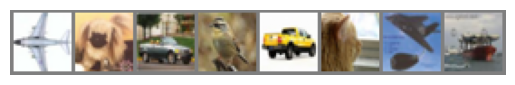

In [7]:
def imshow(img):
    img = img / 2 + 0.5   # unnormalize
    npimg = img.numpy()

    # Correct transpose: (C,H,W) → (H,W,C)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()

# Show images
imshow(torchvision.utils.make_grid(images[:8]))


In [8]:
labels[:8]

tensor([0, 5, 1, 2, 1, 3, 0, 8])

In [9]:
class_names =train_dataset.classes


In [10]:
[class_names[i] for i in labels[:8]]

['airplane',
 'dog',
 'automobile',
 'bird',
 'automobile',
 'cat',
 'airplane',
 'ship']

In [11]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=(3,3),padding="same"),# output: (32, 32,32)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)),# output: (32,16,16)
            nn.Conv2d(32,64,kernel_size=(3,3)), # output : (64,14,14)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)) # output: (64,7,7)
        )
        self.fc_network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7,700),
            nn.ReLU(),
            nn.Linear(700,120),
            nn.ReLU(),
            nn.Linear(120,10)
        )
    def forward(self,x):
        x=self.network(x)
        x=self.fc_network(x)
        return x


In [12]:
CNN()

CNN(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (fc_network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=700, bias=True)
    (2): ReLU()
    (3): Linear(in_features=700, out_features=120, bias=True)
    (4): ReLU()
    (5): Linear(in_features=120, out_features=10, bias=True)
  )
)

In [13]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [14]:
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.5246
Epoch [1/10], Step [200/500], Loss: 1.3686
Epoch [1/10], Step [300/500], Loss: 1.3396
Epoch [1/10], Step [400/500], Loss: 1.3506
Epoch [1/10], Step [500/500], Loss: 0.9341
Epoch [2/10], Step [100/500], Loss: 1.0019
Epoch [2/10], Step [200/500], Loss: 1.0775
Epoch [2/10], Step [300/500], Loss: 0.8690
Epoch [2/10], Step [400/500], Loss: 0.9382
Epoch [2/10], Step [500/500], Loss: 0.8141
Epoch [3/10], Step [100/500], Loss: 0.6841
Epoch [3/10], Step [200/500], Loss: 0.8822
Epoch [3/10], Step [300/500], Loss: 0.9020
Epoch [3/10], Step [400/500], Loss: 0.7215
Epoch [3/10], Step [500/500], Loss: 0.7717
Epoch [4/10], Step [100/500], Loss: 0.9055
Epoch [4/10], Step [200/500], Loss: 0.4888
Epoch [4/10], Step [300/500], Loss: 0.7653
Epoch [4/10], Step [400/500], Loss: 0.4917
Epoch [4/10], Step [500/500], Loss: 0.6322
Epoch [5/10], Step [100/500], Loss: 0.5085
Epoch [5/10], Step [200/500], Loss: 0.4309
Epoch [5/10], Step [300/500], Loss: 0.4825
Epoch [5/10

# With Data Augumentation


In [15]:
transform_aug=transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2,contrast=0.2,saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])
])

In [16]:
train_dataset_Aug = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_aug)
train_loader_aug=DataLoader(train_dataset_Aug,batch_size=batch_size,shuffle=True)


Files already downloaded and verified


In [17]:
# Hyperparameters
num_epochs = 10
learning_rate = 0.001

model_Aug = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_Aug.parameters(), lr=learning_rate)

In [18]:
# Training loop
total_step = len(train_loader)
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        
        # Forward pass
        outputs = model_Aug(images)
        loss = criterion(outputs, labels)
        
        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{total_step}], Loss: {loss.item():.4f}")

# Testing the model
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model_Aug(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Accuracy of the model on the 10000 test images: {100 * correct / total:.2f}%")

Epoch [1/10], Step [100/500], Loss: 1.5401
Epoch [1/10], Step [200/500], Loss: 1.2653
Epoch [1/10], Step [300/500], Loss: 1.2324
Epoch [1/10], Step [400/500], Loss: 1.1717
Epoch [1/10], Step [500/500], Loss: 1.0992
Epoch [2/10], Step [100/500], Loss: 1.0367
Epoch [2/10], Step [200/500], Loss: 0.7918
Epoch [2/10], Step [300/500], Loss: 0.9085
Epoch [2/10], Step [400/500], Loss: 0.9231
Epoch [2/10], Step [500/500], Loss: 0.9068
Epoch [3/10], Step [100/500], Loss: 0.8415
Epoch [3/10], Step [200/500], Loss: 0.8195
Epoch [3/10], Step [300/500], Loss: 0.7892
Epoch [3/10], Step [400/500], Loss: 0.8572
Epoch [3/10], Step [500/500], Loss: 0.7450
Epoch [4/10], Step [100/500], Loss: 0.6350
Epoch [4/10], Step [200/500], Loss: 0.5909
Epoch [4/10], Step [300/500], Loss: 0.5849
Epoch [4/10], Step [400/500], Loss: 0.4930
Epoch [4/10], Step [500/500], Loss: 0.6145
Epoch [5/10], Step [100/500], Loss: 0.3794
Epoch [5/10], Step [200/500], Loss: 0.4708
Epoch [5/10], Step [300/500], Loss: 0.4411
Epoch [5/10